# 03 · Forecasting the VRP
XGBoost and LightGBM with a Huber objective (δ = 0.02), 22 predictors, expanding-window CV with a 21-session purge and 5-session embargo, random search over 40 hyper-parameter sets. XGBoost was selected on mean fold RMSE.

The frozen thesis predictions are used by default (XGBoost is not bit-reproducible across platforms). Set `RETRAIN = True` to re-run the search (~3 min).

In [1]:
from pathlib import Path
import pandas as pd
from vrp import data, features, models, backtest, plots

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"
pd.set_option("display.precision", 4)

In [2]:
RETRAIN = False
raw = data.load_raw(RAW)
feats = features.build_features(raw["underlying"], raw["chain"], raw["macro"])
if RETRAIN:
    out = models.compare_models(feats)
    preds = out["predictions"]
    display(out["summary"])
else:
    preds = pd.read_csv(ROOT / "reports/thesis/oos_predictions.csv", parse_dates=["date"])

## Model vs naive baselines on the same purged folds
`train_mean` = mean target of each fold's training block; `naive_vrp` = VIX/100 − trailing 21d Yang-Zhang vol.

In [3]:
base = models.baseline_fold_metrics(feats, preds)
base.groupby("forecast")[["rmse", "mae", "dir_acc", "corr"]].mean()

,rmse,mae,dir_acc,corr
forecast,,,,
model,0.0662,0.0426,0.9048,0.2119
naive_vrp,0.0766,0.0512,0.8477,0.1103
train_mean,0.0704,0.0491,0.9048,NaN


In [4]:
base.pivot(index="fold", columns="forecast", values="rmse")

forecast,model,naive_vrp,train_mean
fold,,,
1,0.1289,0.1581,0.1295
2,0.0437,0.0490,0.0680
3,0.0510,0.0539,0.0463
4,0.0356,0.0371,0.0386
5,0.0718,0.0848,0.0698


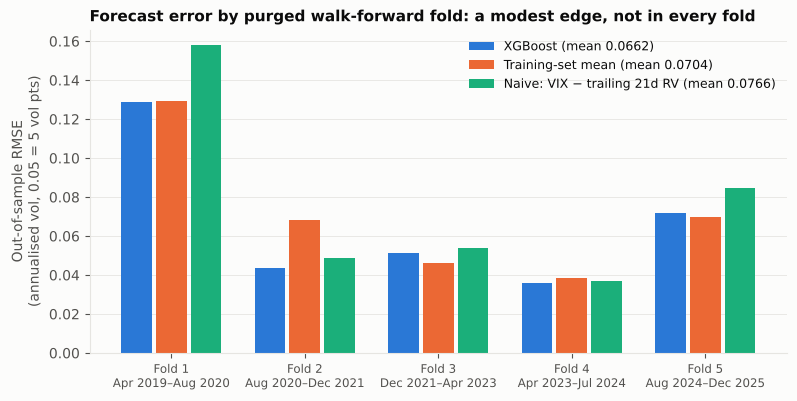

In [5]:
fig = plots.forecast_vs_baselines(base)

**Reading.** RMSE is ~6% below the training-mean baseline and MAE ~13% below, but the model loses to it in folds 3 and 5. Directional accuracy (90.5%) equals the constant forecast's: the VRP was positive on ~90% of test days and the model never predicts a negative value, so directional accuracy carries no information here.

In [6]:
print(f"Share of positive predictions: {100 * (preds.prediction > 0).mean():.1f}%")

Share of positive predictions: 100.0%


## Feature importance (thesis model, refit on the full sample)

In [7]:
pd.read_csv(ROOT / "reports/thesis/feature_importance.csv").head(10)

,feature,importance
0,mfiv,0.1258
1,vix,0.1233
2,ust_3m,0.0786
3,ust_10y,0.0531
4,atm_iv,0.0516
5,rv_gk,0.0512
6,ret_63d,0.0467
7,skew_slope,0.0456
8,skew,0.0453
9,pcr_oi,0.0421
